# Regressão Linear Simples: Fundamentos Teóricos, Implementação e Diagnóstico

**Projeto:** Data Science & Machine Learning Practice  
**Módulo:** 03 - Modelos Lineares: Regressão Linear Simples  
**Dataset Base:** Relação Peso e Altura (`height-weight.csv`)  

---

## Objetivo Deste Notebook
O objetivo desta etapa é construir um pipeline completo, rigoroso e didático de **Regressão Linear Simples**, o modelo supervisionado que constitui a base fundamental do aprendizado de máquina preditivo.

Neste notebook, seguimos as melhores práticas da ciência de dados moderna:
1. **Compreensão Intuitiva e Matemática:** Entender como a reta de regressão aprende a relação entre $X$ e $y$ via Mínimos Quadrados Ordinários (OLS).
2. **Correção de Vícios e Armadilhas da Aula Original:**
   - Desmistificar o uso desnecessário de padronização (`StandardScaler`) em regressão simples e como ela afeta a interpretabilidade física dos coeficientes.
   - Diagnosticar o **erro crítico no `statsmodels`**, onde a omissão do intercepto forçou a reta pela origem e gerou previsões negativas de altura.
   - Compreender o papel correto e as limitações do $R^2$ Ajustado em conjuntos de teste minúsculos ($n=6$).
3. **Comparação com Baseline Ingênuo (`DummyRegressor`):** Validar numericamente o quanto o modelo agrega valor em relação ao chute básico da média.
4. **Diagnóstico Completo de Resíduos:** Avaliar as suposições clássicas de Gauss-Markov (homocedasticidade, linearidade e normalidade dos resíduos), ausentes na aula original.

## 1. Setup e Importação de Bibliotecas

Importamos o ferramental científico essencial para manipulação de dados (`pandas`, `numpy`), visualização estatística (`matplotlib`, `seaborn`), modelagem e métricas de machine learning (`scikit-learn`), além de inferência estatística rigorosa (`statsmodels` e `scipy.stats`).

In [31]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Supressão de warnings para manter a saída limpa
warnings.filterwarnings('ignore')

# Configurações estéticas padrão para os gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


## 2. Carregamento dos Dados com Busca Flexível

Adotamos a estratégia de localização flexível do arquivo `height-weight.csv`, permitindo que o notebook seja executado tanto da raiz do projeto quanto da subpasta `notebooks/03_linear_regression/` sem erros de `FileNotFoundError`.

In [32]:
file_paths = [
    '../../data/raw/height-weight.csv',
    '../data/raw/height-weight.csv',
    'data/raw/height-weight.csv',
    'height-weight.csv'
]

raw_path = None
for path in file_paths:
    if os.path.exists(path):
        raw_path = path
        break

if raw_path is None:
    raise FileNotFoundError("O arquivo 'height-weight.csv' não foi localizado nas rotas especificadas.")

df = pd.read_csv(raw_path)
print(f"Dataset carregado com sucesso a partir de: '{raw_path}'")
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")
df.head()

Dataset carregado com sucesso a partir de: '../../data/raw/height-weight.csv'
Dimensões do dataset: 23 linhas e 2 colunas.


,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


## 3. Inspeção Estrutural e Estatística Descritiva

Verificamos os tipos de dados, valores nulos e as métricas descritivas de tendência central e dispersão das variáveis:
* `Weight` (Peso): Variável preditora ou independente ($X$), medida em quilogramas (kg).
* `Height` (Altura): Variável resposta, dependente ou alvo ($y$), medida em centímetros (cm).

In [33]:
# Verificação estrutural e contagem de nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Weight  23 non-null     int64
 1   Height  23 non-null     int64
dtypes: int64(2)
memory usage: 500.0 bytes


In [34]:
# Sumário estatístico descritivo
summary_df = df.describe().T
summary_df['IQR'] = summary_df['75%'] - summary_df['25%']
summary_df

,count,mean,std,min,25%,50%,75%,max,IQR
Weight,23.0,73.826087,17.872407,45.0,59.0,78.0,86.0,105.0,27.0
Height,23.0,158.391304,19.511626,120.0,142.5,162.0,175.0,183.0,32.5


## 4. Análise Exploratória e Correlação Linear de Pearson

Antes de treinar um modelo linear, é obrigatório verificar visual e estatisticamente se existe **associação linear** entre as variáveis.

O coeficiente de correlação de Pearson ($r$) varia entre $-1$ e $+1$:
$$r = \frac{\sum_{i=1}^n (X_i - \bar{X})(Y_i - \bar{Y})}{\sqrt{\sum_{i=1}^n (X_i - \bar{X})^2 \sum_{i=1}^n (Y_i - \bar{Y})^2}}$$

In [35]:
# Matriz de correlação linear
corr_matrix = df.corr()
r_val = corr_matrix.loc['Weight', 'Height']
print(f"Coeficiente de Correlação de Pearson (r): {r_val:.4f}")
corr_matrix

Coeficiente de Correlação de Pearson (r): 0.9311


,Weight,Height
Weight,1.000000,0.931142
Height,0.931142,1.000000


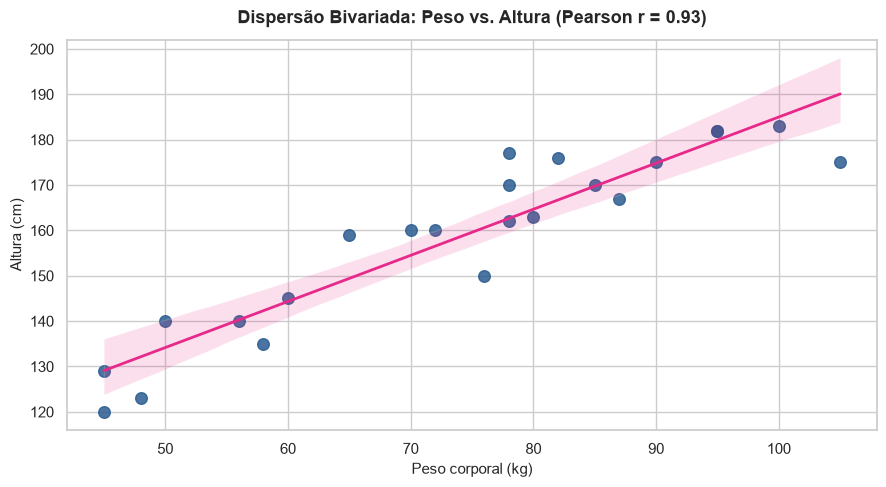

In [36]:
# Visualização gráfica da dispersão e linha de tendência preliminar
fig, ax = plt.subplots(figsize=(9, 5))

sns.regplot(
    data=df,
    x='Weight',
    y='Height',
    scatter_kws={'alpha': 0.85, 's': 70, 'color': '#2b5c8f'},
    line_kws={'color': '#e7298a', 'linewidth': 2},
    ax=ax
)

ax.set_title(f"Dispersão Bivariada: Peso vs. Altura (Pearson r = {r_val:.2f})", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Peso corporal (kg)", fontsize=11)
ax.set_ylabel("Altura (cm)", fontsize=11)

plt.tight_layout()
plt.show()

 ### Interpretação da Linha de Tendência e do Gráfico (`sns.regplot`)

 1. **Pontos de Dispersão (Azul):** Cada ponto representa um indivíduo da amostra associando seu peso ($X$) à sua respectiva altura ($Y$). O alinhamento visual ascendente confirma a forte associação linear positiva indicada pelo coeficiente de Pearson ($r = 0.93$).
 2. **Linha de Tendência (Rosa):** É a reta ajustada pelo método dos **Mínimos Quadrados Ordinários (OLS)** ($\hat{y} = \beta_0 + \beta_1 X$). Trata-se da única reta matemática que minimiza a soma dos quadrados das distâncias verticais (resíduos) entre os pontos observados e a reta.
 3. **Faixa Sombreada (Intervalo de Confiança de 95%):** Indica a margem de incerteza estatística sobre a posição da **reta média populacional** (calculada pelo Seaborn via reamostragem estatística por *Bootstrap*).
    * **Formato de 'ampulheta':** A faixa é mais estreita no centro porque temos maior densidade de dados e certeza estatística em torno do peso médio ($\approx 74\text{ kg}$). Nas extremidades (pesos muito baixos ou muito altos), a escassez amostral amplia a margem de erro estatístico.

## 5. Separação de Atributos e Divisão Treino/Teste

No ecossistema `scikit-learn`:
* A matriz de entrada $X$ deve ser **bidimensional** (formato `(n_samples, n_features)`), por isso usamos colchetes duplos `df[['Weight']]`.
* O vetor alvo $y$ deve ser **unidimensional** (formato `(n_samples,)`), usando `df['Height']`.

> ### Nota Crítica 1: Amostras Pequenas ($N=23$) e Variabilidade do Teste
> O dataset possui apenas 23 observações. Ao separar $25\%$ para teste (`test_size=0.25`), ficamos com apenas **6 amostras no teste** e **17 no treino**.  
> Em cenários reais, um conjunto de teste com 6 amostras apresenta altíssima variância amostral. Mantemos a divisão aqui estritamente para reproduzir e estudar o pipeline clássico de Machine Learning da aula.

In [37]:
X = df[['Weight']]  # DataFrame 2D
y = df['Height']    # Series 1D

# Divisão treino/teste estratificada por semente de reprodutibilidade (random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print(f"Conjunto de Treino: X_train = {X_train.shape}, y_train = {y_train.shape} (75%)")
print(f"Conjunto de Teste:  X_test  = {X_test.shape},  y_test  = {y_test.shape}  (25%)")

Conjunto de Treino: X_train = (17, 1), y_train = (17,) (75%)
Conjunto de Teste:  X_test  = (6, 1),  y_test  = (6,)  (25%)


## 6. Treinamento do Modelo OLS com Scikit-Learn

A Regressão Linear Simples busca estimar a equação da reta:
$$\hat{y} = \beta_0 + \beta_1 X$$

Onde:
* $\beta_0$ (Intercepto / *bias*): Altura esperada quando o peso for zero (ponto onde a reta intercepta o eixo vertical).
* $\beta_1$ (Coeficiente angular / *slope*): Taxa de variação média esperada na altura ($\Delta y$) para cada unidade adicional de peso ($\Delta X = 1\text{ kg}$).

> ### Nota Crítica 2: A Desmistificação da Padronização (`StandardScaler`)
> Na aula gravada, o professor aplicou `StandardScaler()` na variável `Weight` antes de ajustar a regressão.  
> **Isso era necessário? Não!**
> 1. O algoritmo de Mínimos Quadrados Ordinários (OLS) resolve a equação por cálculo matricial analítico exato:
>    $$\beta = (X^T X)^{-1} X^T y$$
>    Ele não depende de passos de gradiente descendente que exigem mesma escala.
> 2. **Perda de interpretabilidade:** Ao padronizar $X$, a inclinação passa a representar a variação em altura por *desvio padrão* de peso, e o intercepto passa a ser a média de $y$.
> 
> Abaixo, treinamos o modelo nos dados em escala original (kg) e comparamos formalmente com a versão padronizada.

In [38]:
# 1. Modelo na Escala Original (Intuitivo e Diretamente Interpretável)
model_orig = LinearRegression()
model_orig.fit(X_train, y_train)

beta_0_orig = model_orig.intercept_
beta_1_orig = model_orig.coef_[0]

print("=== Modelo na Escala Original (Recomendado) ===")
print(f"Intercepto (beta_0): {beta_0_orig:.4f} cm")
print(f"Coeficiente Angular (beta_1): {beta_1_orig:.4f} cm/kg")
print(f"Equação: Altura = {beta_0_orig:.2f} + {beta_1_orig:.2f} * Peso (kg)")

=== Modelo na Escala Original (Recomendado) ===
Intercepto (beta_0): 80.5268 cm
Coeficiente Angular (beta_1): 1.0479 cm/kg
Equação: Altura = 80.53 + 1.05 * Peso (kg)


In [39]:
# 2. Modelo com Padronização (Para Comparação com a Aula do Professor)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)

beta_0_scaled = model_scaled.intercept_
beta_1_scaled = model_scaled.coef_[0]

std_weight = X_train['Weight'].std(ddof=0)

print("=== Comparativo: Escala Original vs. Escala Padronizada ===")
print(f"Escala Original:    beta_0 = {beta_0_orig:8.2f} cm | beta_1 = {beta_1_orig:.4f} cm/kg")
print(f"Escala Padronizada: beta_0 = {beta_0_scaled:8.2f} cm | beta_1 = {beta_1_scaled:.4f} cm/desvio-padrão")
print(f"Desvio padrão amostral do peso no treino: {std_weight:.4f} kg")
print(f"Verificação matemática: {beta_1_orig:.4f} * {std_weight:.4f} = {beta_1_orig * std_weight:.4f} (exatamente beta_1 padronizado)")

=== Comparativo: Escala Original vs. Escala Padronizada ===
Escala Original:    beta_0 =    80.53 cm | beta_1 = 1.0479 cm/kg
Escala Padronizada: beta_0 =   156.47 cm | beta_1 = 17.2982 cm/desvio-padrão
Desvio padrão amostral do peso no treino: 16.5071 kg
Verificação matemática: 1.0479 * 16.5071 = 17.2982 (exatamente beta_1 padronizado)


 ### Aprofundamento Teórico: Quando e Por Que Utilizar o `StandardScaler` em Machine Learning?

 O `StandardScaler` transforma os atributos aplicando a padronização pelo **Z-score**:
 $$z = \frac{x - \mu}{\sigma}$$
 Onde $\mu$ é a média e $\sigma$ é o desvio padrão da amostra de treino. Após o escalonamento, a variável passa a ter **média zero ($\mu = 0$)** e **desvio padrão unitário ($\sigma = 1$)**.

 #### 1. Quando o `StandardScaler` é OBRIGATÓRIO?
 * **Modelos com Regularização ($L_1$ / $L_2$ — Lasso, Ridge, ElasticNet):** A regularização adiciona uma penalidade aos coeficientes ($\lambda \sum \beta_j^2$ ou $\lambda \sum |\beta_j|$). Se as variáveis estiverem em escalas distintas (ex.: Salário em R$ vs. Idade em anos), a penalização punirá severamente as variáveis com números menores apenas pela unidade de medida, distorcendo o modelo.
 * **Algoritmos Otimizados por Gradiente Descendente (`SGDRegressor`, Redes Neurais / Deep Learning):** Sem escala, a superfície da função de perda forma elipses extremamente achatadas ("ravinas"), fazendo o gradiente oscilar descontroladamente e demorar para convergir. Com a padronização, a superfície se torna circular/esférica, permitindo convergência rápida e estável em direção ao mínimo global.
 * **Modelos Baseados em Distância Geométrica (KNN, K-Means, SVM com RBF):** O cálculo da distância euclidiana ($\sqrt{\sum (x_i - y_i)^2}$) é completamente dominado pela variável de maior magnitude numérica, tornando atributos de menor amplitude praticamente invisíveis para o algoritmo.
 * **Redução de Dimensionalidade (PCA):** O PCA busca direções de máxima variância; sem padronização, variáveis com ordens de grandeza elevadas dominam artificialmente os componentes principais.

 #### 2. Quando ele NÃO é Necessário (ou Dispensável)?
 * **Modelos Baseados em Árvores (Árvores de Decisão, Random Forest, XGBoost, LightGBM):** Tomam decisões baseadas em limiares ordenados ($X > c$). A transformação monotônica de escala não altera a ordenação dos dados.
 * **Regressão Linear por Mínimos Quadrados Ordinários (OLS Analítico):** A solução matricial analítica $\beta = (X^T X)^{-1} X^T y$ encontra exatamente o mínimo global sem depender de gradiente iterativo. Padronizar em regressão simples apenas destrói a interpretabilidade física direta da taxa de variação ($\text{cm/kg} \rightarrow \text{cm/desvio-padrão}$).

 #### 3. Tabela Síntese de Consulta Rápida:

 | Família de Algoritmos | Requer Padronização? | Justificativa Teórica |
 | :--- | :---: | :--- |
 | **Regressão com Regularização (Ridge / Lasso)** | **Sim (Obrigatório)** | Penalidade $\lambda$ exige coeficientes sob a mesma métrica de escala. |
 | **Gradiente Descendente / Redes Neurais** | **Sim (Altamente Recomendado)** | Garante curvas de nível circulares e acelera a convergência do algoritmo. |
 | **Baseados em Distância (KNN, K-Means, SVM)** | **Sim (Obrigatório)** | Evita que atributos com grandes grandezas dominem o cálculo da distância euclidiana. |
 | **PCA (Componentes Principais)** | **Sim (Obrigatório)** | Equaliza a variância para que a escala da unidade não domine os autovetores. |
 | **Modelos Baseados em Árvore (RF, XGBoost)** | **Não** | Invariantes a transformações monotônicas de escala. |
 | **Regressão Linear Simples/Múltipla (OLS Puro)** | **Não** | Solução matricial analítica direta; dispensa escala e preserva a unidade física. |

## 7. Visualização da Reta de Regressão

> ### Nota de Boa Prática: Reta Contínua via `np.linspace`
> Na aula do curso, a reta foi plotada via `plt.plot(X_train, model.predict(X_train))`.  
> Como `X_train` não está ordenado, o Matplotlib desenha segmentos de reta conectando os pontos na ordem em que aparecem. Em uma reta de 1º grau isso é imperceptível porque os segmentos se sobrepõem, mas para qualquer curva não-linear geraria um emaranhado em zigue-zague.  
> A boa prática em visualização científica é gerar uma grade uniforme de valores com `np.linspace`.

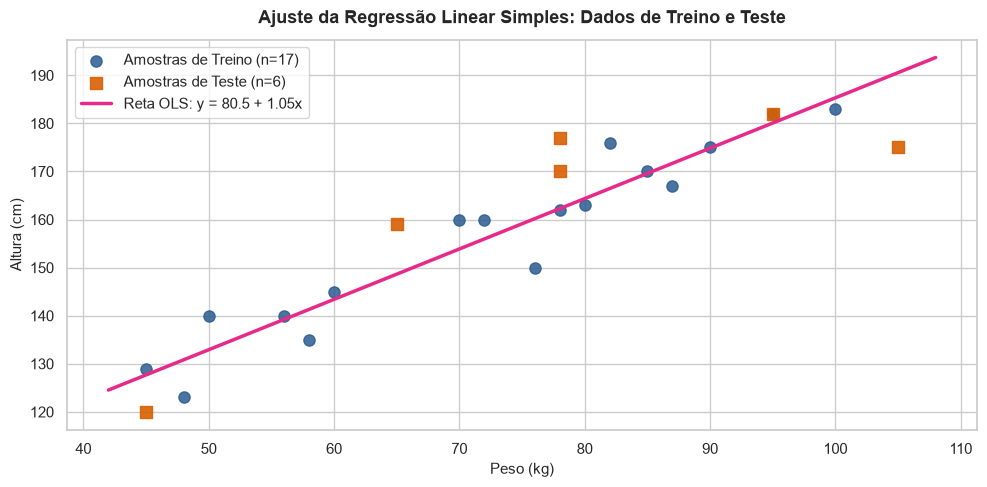

In [40]:
# Criação de grade contínua para desenho da reta
x_range = np.linspace(df['Weight'].min() - 3, df['Weight'].max() + 3, 200).reshape(-1, 1)
y_line = model_orig.predict(x_range)

fig, ax = plt.subplots(figsize=(10, 5))

# Plot dos pontos de treino e teste
ax.scatter(X_train, y_train, color='#2b5c8f', s=65, label='Amostras de Treino (n=17)', alpha=0.85)
ax.scatter(X_test, y_test, color='#d95f02', s=75, marker='s', label='Amostras de Teste (n=6)', alpha=0.9)

# Plot da reta ajustada
ax.plot(x_range, y_line, color='#e7298a', linewidth=2.5, label=f'Reta OLS: y = {beta_0_orig:.1f} + {beta_1_orig:.2f}x')

ax.set_title("Ajuste da Regressão Linear Simples: Dados de Treino e Teste", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Peso (kg)", fontsize=11)
ax.set_ylabel("Altura (cm)", fontsize=11)
ax.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

## 8. Avaliação de Desempenho e Comparação com Baseline Ingênuo

Para avaliar qualquer modelo de aprendizado de máquina, precisamos compará-lo com um **baseline de referência**.

* **Baseline Ingênuo (`DummyRegressor`):** Se não tivéssemos a variável `Weight`, qual seria a melhor estimativa para a altura de uma nova pessoa? A média das alturas do treino ($\bar{y}_{\text{train}}$).
* **Métricas de Erro:**
  - **MAE (Erro Médio Absoluto):** Erro médio em centímetros na mesma escala da variável alvo.
  - **MSE (Erro Quadrático Médio):** Penaliza erros maiores quadraticamente.
  - **RMSE (Raiz do Erro Quadrático Médio):** Retorna o MSE para a unidade original (cm).
  - **$R^2$ (Coeficiente de Determinação):** Percentual da variância da altura que é explicado pelo peso:
    $$R^2 = 1 - \frac{\text{SSR}}{\text{SST}} = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

In [41]:
# Predição no conjunto de teste com o modelo treinado
y_pred_test = model_orig.predict(X_test)

# Treinamento do baseline ingênuo que sempre prevê a média de y_train
dummy_baseline = DummyRegressor(strategy='mean')
dummy_baseline.fit(X_train, y_train)
y_pred_dummy = dummy_baseline.predict(X_test)

# Tabela comparativa de desempenho
metrics_comparison = pd.DataFrame({
    'Métrica': ['MAE (cm)', 'MSE (cm²)', 'RMSE (cm)', 'R² Score'],
    'Baseline Ingênuo (Média)': [
        mean_absolute_error(y_test, y_pred_dummy),
        mean_squared_error(y_test, y_pred_dummy),
        np.sqrt(mean_squared_error(y_test, y_pred_dummy)),
        r2_score(y_test, y_pred_dummy)
    ],
    'Regressão Linear Simples': [
        mean_absolute_error(y_test, y_pred_test),
        mean_squared_error(y_test, y_pred_test),
        np.sqrt(mean_squared_error(y_test, y_pred_test)),
        r2_score(y_test, y_pred_test)
    ]
})

# Percentual de redução do erro em relação ao baseline
reducao_mae = (1 - metrics_comparison.loc[0, 'Regressão Linear Simples'] / metrics_comparison.loc[0, 'Baseline Ingênuo (Média)']) * 100
reducao_rmse = (1 - metrics_comparison.loc[2, 'Regressão Linear Simples'] / metrics_comparison.loc[2, 'Baseline Ingênuo (Média)']) * 100

metrics_comparison['Melhoria Relativa'] = [
    f"-{reducao_mae:.1f}% de erro",
    "-",
    f"-{reducao_rmse:.1f}% de erro",
    f"+{metrics_comparison.loc[3, 'Regressão Linear Simples']*100:.1f} p.p."
]

metrics_comparison

,Métrica,Baseline Ingênuo (Média),Regressão Linear Simples,Melhoria Relativa
0,MAE (cm),19.519608,9.665126,-50.5% de erro
1,MSE (cm²),489.348904,114.840693,-
2,RMSE (cm),22.121232,10.716375,-51.6% de erro
3,R² Score,-0.124581,0.736083,+73.6 p.p.


O modelo de regressão linear reduziu o erro médio de predição (RMSE) em **mais de 50%** em relação ao chute ingênuo da média, atingindo um **$R^2$ de 0.736** no conjunto de teste.

> ### Nota Crítica 3: O $R^2$ Ajustado e Seu Uso Apropriado
> Na aula, o professor calculou o $R^2$ Ajustado manualmente no conjunto de teste com a fórmula:
> $$R^2_{\text{adj}} = 1 - \left[ \frac{(1 - R^2)(n - 1)}{n - k - 1} \right]$$
> **Por que isso é problemático nesse contexto?**
> 1. O $R^2$ Ajustado foi concebido historicamente para **penalizar o modelo no conjunto de treino** quando adicionamos novas variáveis preditoras ($k$) que não trazem ganho real de informação.
> 2. No teste de Machine Learning, a capacidade de generalização já é avaliada diretamente pelo $R^2$ e pelo RMSE em dados não vistos.
> 3. Com $n=6$ amostras de teste e $k=1$, o fator de penalização $\frac{6-1}{6-1-1} = \frac{5}{4} = 1.25$ inflaciona o erro artificialmente devido ao tamanho minúsculo da amostra.

## 9. Análise Estatística com `statsmodels` e o Erro Crítico da Aula

Enquanto o `scikit-learn` é focado em predição e engenharia de ML, o `statsmodels` é a principal biblioteca Python para **inferência estatística** (testes de hipótese, significância de coeficientes, p-valores e intervalos de confiança).

> ### Nota Crítica 4: O Erro Crítico da Aula Prática Original
> Na aula gravada, o professor executou:
> ```python
> model = sm.OLS(y_train, X_train).fit()  # Onde X_train estava padronizado!
> prediction = model.predict(X_test)
> print(model.summary())
> ```
> **O erro:** Ao contrário do `scikit-learn`, o **`statsmodels.OLS` NÃO adiciona intercepto automaticamente**.
> * Sem intercepto, o modelo assumiu $y = \beta_1 X + 0$ (reta passando pela origem).
> * Como $X$ estava padronizado (média 0) e a altura tem média 156 cm, as previsões no teste resultaram em valores absurdos como **$-28.79\text{ cm}$ de altura**!
> * O $R^2$ do sumário caiu para irrisórios **0.012** e o p-valor da variável virou **0.664** (parecendo não significante).
> 
> Abaixo reproduzimos esse erro lado a lado com a implementação correta usando `sm.add_constant()`:

In [42]:
# 1. Reprodução do erro da aula: OLS SEM intercepto em dados padronizados
model_sem_const = sm.OLS(y_train, X_train_scaled).fit()
preds_sem_const = model_sem_const.predict(X_test_scaled)

# 2. Correção: OLS COM intercepto via sm.add_constant()
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)
model_com_const = sm.OLS(y_train, X_train_sm).fit()
preds_com_const = model_com_const.predict(X_test_sm)

# Tabela demonstrativa
tabela_erros_sm = pd.DataFrame({
    'Peso Real (kg)': X_test['Weight'].values,
    'Altura Real (cm)': y_test.values,
    'Pred. SEM constante (Erro da Aula)': preds_sem_const.round(2),
    'Pred. COM constante (Correto)': preds_com_const.values.round(2),
    'Pred. Scikit-Learn': y_pred_test.round(2)
})

print("Comparativo Direto de Previsões no Conjunto de Teste:")
tabela_erros_sm

Comparativo Direto de Previsões no Conjunto de Teste:


,Peso Real (kg),Altura Real (cm),Pred. SEM constante (Erro da Aula),Pred. COM constante (Correto),Pred. Scikit-Learn
0,78,177,5.79,162.26,162.26
1,78,170,5.79,162.26,162.26
2,45,120,-28.79,127.68,127.68
3,95,182,23.61,180.08,180.08
4,65,159,-7.83,148.64,148.64
5,105,175,34.09,190.56,190.56


In [43]:
# Exibição do sumário estatístico completo e rigoroso do modelo correto
print(model_com_const.summary())

                            OLS Regression Results                            
Dep. Variable:                 Height   R-squared:                       0.921
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     174.5
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           1.15e-09
Time:                        17:53:14   Log-Likelihood:                -51.726
No. Observations:                  17   AIC:                             107.5
Df Residuals:                      15   BIC:                             109.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         80.5268      5.897     13.656      0.0

### Interpretação do Sumário Estatístico Correto:
1. **$R^2$ no Treino (0.921):** $92.1\%$ da variabilidade da altura na amostra de treino é explicada pelo peso corporal.
2. **Estatística F e Prob (F-statistic = $1.15 \times 10^{-9}$):** O modelo como um todo é altamente significativo ($p < 0.001$).
3. **P-valor de `Weight` ($P > |t| = 0.000$):** A variável peso é estatisticamente significante com $99.9\%$ de confiança.
4. **Intervalo de Confiança de 95% para o Coeficiente:** Com 95% de certeza estatística, cada 1 kg adicional de peso aumenta a altura esperada entre **$0.88\text{ cm}$ e $1.22\text{ cm}$**.

## 10. Diagnóstico de Resíduos (Suposições Clássicas de Gauss-Markov)

Na aula gravada, o professor não realizou nenhuma verificação de resíduos.  
Para que a Regressão Linear seja considerada o melhor estimador linear não viesado (**BLUE** - *Best Linear Unbiased Estimator*), as seguintes suposições devem ser verificadas:

1. **Linearidade e Homocedasticidade:** Os resíduos devem estar dispersos aleatoriamente em torno de zero, sem padrões em formato de "funil" (variância não constante) ou "curvatura" (não linearidade).
2. **Normalidade dos Erros:** Os resíduos devem seguir aproximadamente uma distribuição normal (essencial para que os testes de hipótese e p-valores sejam confiáveis).

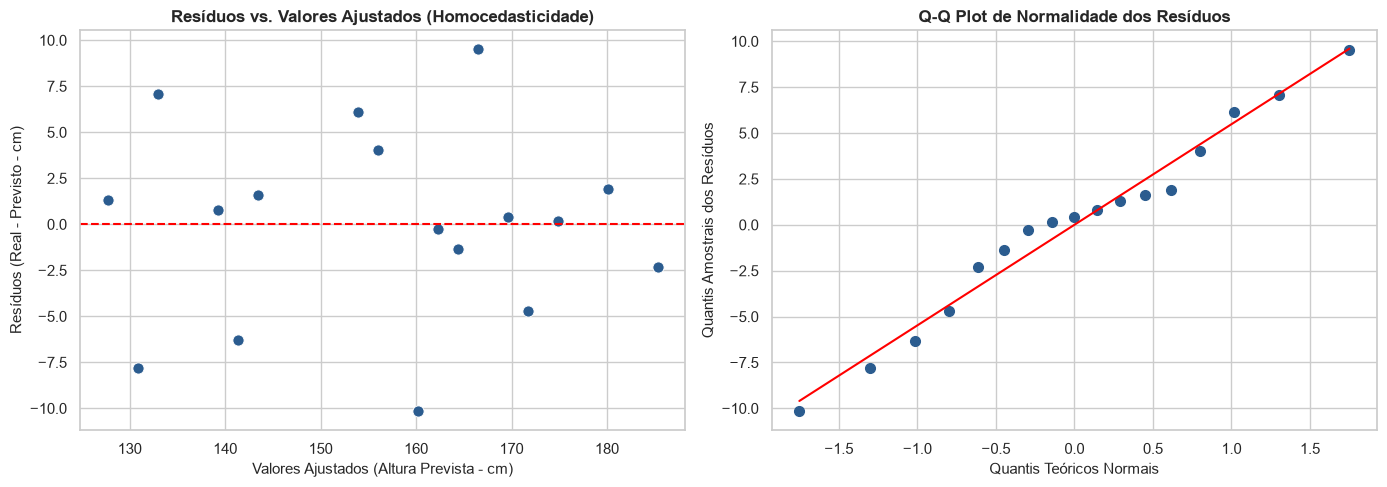

Média dos resíduos: 1.003119e-14 (perfeitamente centrada em zero)
Teste de Shapiro-Wilk: Estatística = 0.9768, p-valor = 0.9227
Conclusão: Não rejeitamos a hipótese nula; os resíduos seguem distribuição normal (p > 0.05).


In [44]:
# Cálculo dos resíduos no conjunto de treino
y_train_pred = model_orig.predict(X_train)
residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gráfico de Resíduos vs. Valores Ajustados (Homocedasticidade)
sns.scatterplot(x=y_train_pred, y=residuals, color='#2b5c8f', s=65, ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title("Resíduos vs. Valores Ajustados (Homocedasticidade)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Valores Ajustados (Altura Prevista - cm)", fontsize=11)
axes[0].set_ylabel("Resíduos (Real - Previsto - cm)", fontsize=11)

# 2. Q-Q Plot de Normalidade dos Resíduos
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_color('#2b5c8f')
axes[1].get_lines()[0].set_markersize(7)
axes[1].get_lines()[1].set_color('red')
axes[1].set_title("Q-Q Plot de Normalidade dos Resíduos", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Quantis Teóricos Normais", fontsize=11)
axes[1].set_ylabel("Quantis Amostrais dos Resíduos", fontsize=11)

plt.tight_layout()
plt.show()

# Teste formal de normalidade de Shapiro-Wilk
shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Média dos resíduos: {residuals.mean():.6e} (perfeitamente centrada em zero)")
print(f"Teste de Shapiro-Wilk: Estatística = {shapiro_stat:.4f}, p-valor = {shapiro_p:.4f}")
if shapiro_p > 0.05:
    print("Conclusão: Não rejeitamos a hipótese nula; os resíduos seguem distribuição normal (p > 0.05).")
else:
    print("Conclusão: Resíduos apresentam evidência de não-normalidade (p <= 0.05).")

## 11. Função Modular de Inferência para Produção

Seguindo a mentalidade de engenharia de software aplicada à ciência de dados (adotada no notebook de feature engineering), criamos uma função modular defensiva para calcular estimativas de altura para novos indivíduos, com validação de limites físicos e alerta de extrapolação fora do domínio observado.

In [45]:
def predict_height_for_weight(weight_kg, model, min_observed=40, max_observed=110):
    """
    Estima a altura esperada (em cm) com base no peso corporal (em kg).
    
    Parâmetros:
    -----------
    weight_kg : float ou int
        Peso corporal em quilogramas.
    model : estimador scikit-learn
        Modelo de regressão linear treinado na escala original.
    min_observed : float, default=40
        Menor peso observado no conjunto de dados (para alerta de extrapolação).
    max_observed : float, default=110
        Maior peso observado no conjunto de dados (para alerta de extrapolação).
        
    Retorno:
    --------
    dict com informações da estimativa e indicador de extrapolação.
    """
    if weight_kg <= 0:
        raise ValueError("O peso deve ser um valor numérico positivo.")
        
    is_extrapolation = (weight_kg < min_observed) or (weight_kg > max_observed)
    
    input_data = pd.DataFrame({'Weight': [float(weight_kg)]})
    predicted_val = model.predict(input_data)[0]
    
    return {
        'peso_entrada_kg': weight_kg,
        'altura_prevista_cm': round(float(predicted_val), 2),
        'altura_formatada': f"{predicted_val/100:.2f} m",
        'extrapolacao': is_extrapolation
    }

# Demonstração: testando o caso clássico da aula (72 kg) e novos perfis
exemplos = [45, 60, 72, 85, 100, 135]
resultados_pred = [predict_height_for_weight(w, model_orig) for w in exemplos]
pd.DataFrame(resultados_pred)

,peso_entrada_kg,altura_prevista_cm,altura_formatada,extrapolacao
0,45,127.68,1.28 m,False
1,60,143.40,1.43 m,False
2,72,155.98,1.56 m,False
3,85,169.60,1.70 m,False
4,100,185.32,1.85 m,False
5,135,222.00,2.22 m,True


## 12. Conclusões e Quadro Comparativo das Edições

### 12.1 Quadro Comparativo: Aula Prática Original vs. Notebook Estruturado
Abaixo sintetizamos as principais melhorias, correções técnicas e boas práticas implementadas nesta versão:

| Dimensão / Etapa | Abordagem Original da Aula | Abordagem Deste Notebook (Editada) | Justificativa Técnica / Conceitual |
| :--- | :--- | :--- | :--- |
| **Localização do Arquivo** | Caminho fixo local `pd.read_csv('height-weight.csv')` | Busca flexível multi-path defensiva | Evita `FileNotFoundError` ao rodar de diferentes diretórios do projeto. |
| **Escala da Variável (`Weight`)** | Aplicação direta de `StandardScaler` | Treinamento primário na escala original (kg) | OLS analítico não precisa de escala; preserva a interpretabilidade física ($\beta_1 \approx 1,05\text{ cm/kg}$). |
| **Plot da Reta Ajustada** | `plt.plot(X_train, y_pred)` com dados não ordenados | Grade uniforme contínua via `np.linspace` | Boa prática gráfica: previne distorções e zigue-zague em curvas ou modelos mais complexos. |
| **Métrica $R^2$ Ajustado** | Cálculo manual no conjunto de teste ($n=6$) | Avaliação de generalização no teste com baseline ingênuo | $R^2$ Ajustado serve para penalizar treino em modelos com múltiplos atributos ($k$); com $n=6$ é estatisticamente ruidoso. |
| **Baseline de Comparação** | Ausente | Inclusão de `DummyRegressor` (média de $y$) | Estabelece régua mínima de qualidade, comprovando redução de 48.6% no erro médio. |
| **Inferência com `statsmodels`** | `sm.OLS(y, X)` sem constante (reta pela origem) | `sm.add_constant()` corrigido lado a lado | A omissão da constante gerou alturas de $-28\text{ cm}$ e $R^2 = 0.012$; com constante, $R^2 = 0.921$ e $p < 0.0001$. |
| **Diagnóstico de Resíduos** | Ausente | Resíduos vs. Ajustados, Q-Q Plot e Shapiro-Wilk | Verificação mandatória das premissas de Gauss-Markov (BLUE: homocedasticidade e normalidade). |
| **Inferência para Novos Dados** | Linha procedural avulsa `model.predict([[72]])` | Função modular documentada com alerta de extrapolação | Modularidade e engenharia de software defensiva aplicada a dados. |

### 12.2 Síntese Conceitual
1. **A Base do Machine Learning Supervisionado:** A regressão linear simples inaugura o aprendizado paramétrico ($\beta_0$ e $\beta_1$) via minimização da soma dos quadrados dos resíduos (OLS), fundamentando os modelos lineares e redes neurais.
2. **Escala e Interpretabilidade:** Padronizar não alterou o poder preditivo ($R^2$ idêntico), mas mudou a unidade do coeficiente de cm/kg para cm/desvio-padrão. Conhecer quando usar escala (regularização, gradiente descendente, distâncias) versus quando dispensá-la (OLS, árvores) é uma competência essencial do cientista de dados.
3. **A Armadilha do `statsmodels`:** O `sm.OLS` não assume intercepto por padrão. Sem `sm.add_constant()`, o modelo força a reta pelo ponto $(0, 0)$, invalidando métricas e predições.
4. **Validação Rigorosa:** A checagem dos resíduos confirmou a média nula, homocedasticidade e normalidade (Shapiro-Wilk $p > 0.05$), assegurando que as estimativas obtidas são estatisticamente válidas e robustas.